# **Heating and Cooling Load Requirement Prediction Of Buildings**

- **DATASET CITATION:**
A. Tsanas and A. Xifara. "Energy Efficiency," UCI Machine Learning Repository, 2012. [Online]. Available: https://doi.org/10.24432/C51307.

### Dataset Summary
Features:
- X1	Relative Compactness
- X2	Surface Area
- X3	Wall Area
- X4	Roof Area
- X5	Overall Height
- X6	Orientation
- X7	Glazing Area
- X8	Glazing Area Distribution

Outputs(Continous):
- y1	Heating Load
- y2	Cooling Load

In [172]:
!pip install ucimlrepo

In [173]:
from ucimlrepo import fetch_ucirepo

energy_efficiency = fetch_ucirepo(id=242)
X = energy_efficiency.data.features
y = energy_efficiency.data.targets

energy_efficiency.variables

,name,role,type,demographic,description,units,missing_values
0,X1,Feature,Continuous,None,Relative Compactness,None,no
1,X2,Feature,Continuous,None,Surface Area,None,no
2,X3,Feature,Continuous,None,Wall Area,None,no
3,X4,Feature,Continuous,None,Roof Area,None,no
4,X5,Feature,Continuous,None,Overall Height,None,no
5,X6,Feature,Integer,None,Orientation,None,no
6,X7,Feature,Continuous,None,Glazing Area,None,no
7,X8,Feature,Integer,None,Glazing Area Distribution,None,no
8,Y1,Target,Continuous,None,Heating Load,None,no
9,Y2,Target,Continuous,None,Cooling Load,None,no


## **Exploratory Data Analysis and Feature Selection**
- Done to observe relationships of the features with output variables

In [174]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_regression

In [175]:
X.describe()

,X1,X2,X3,X4,X5,X6,X7,X8
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000


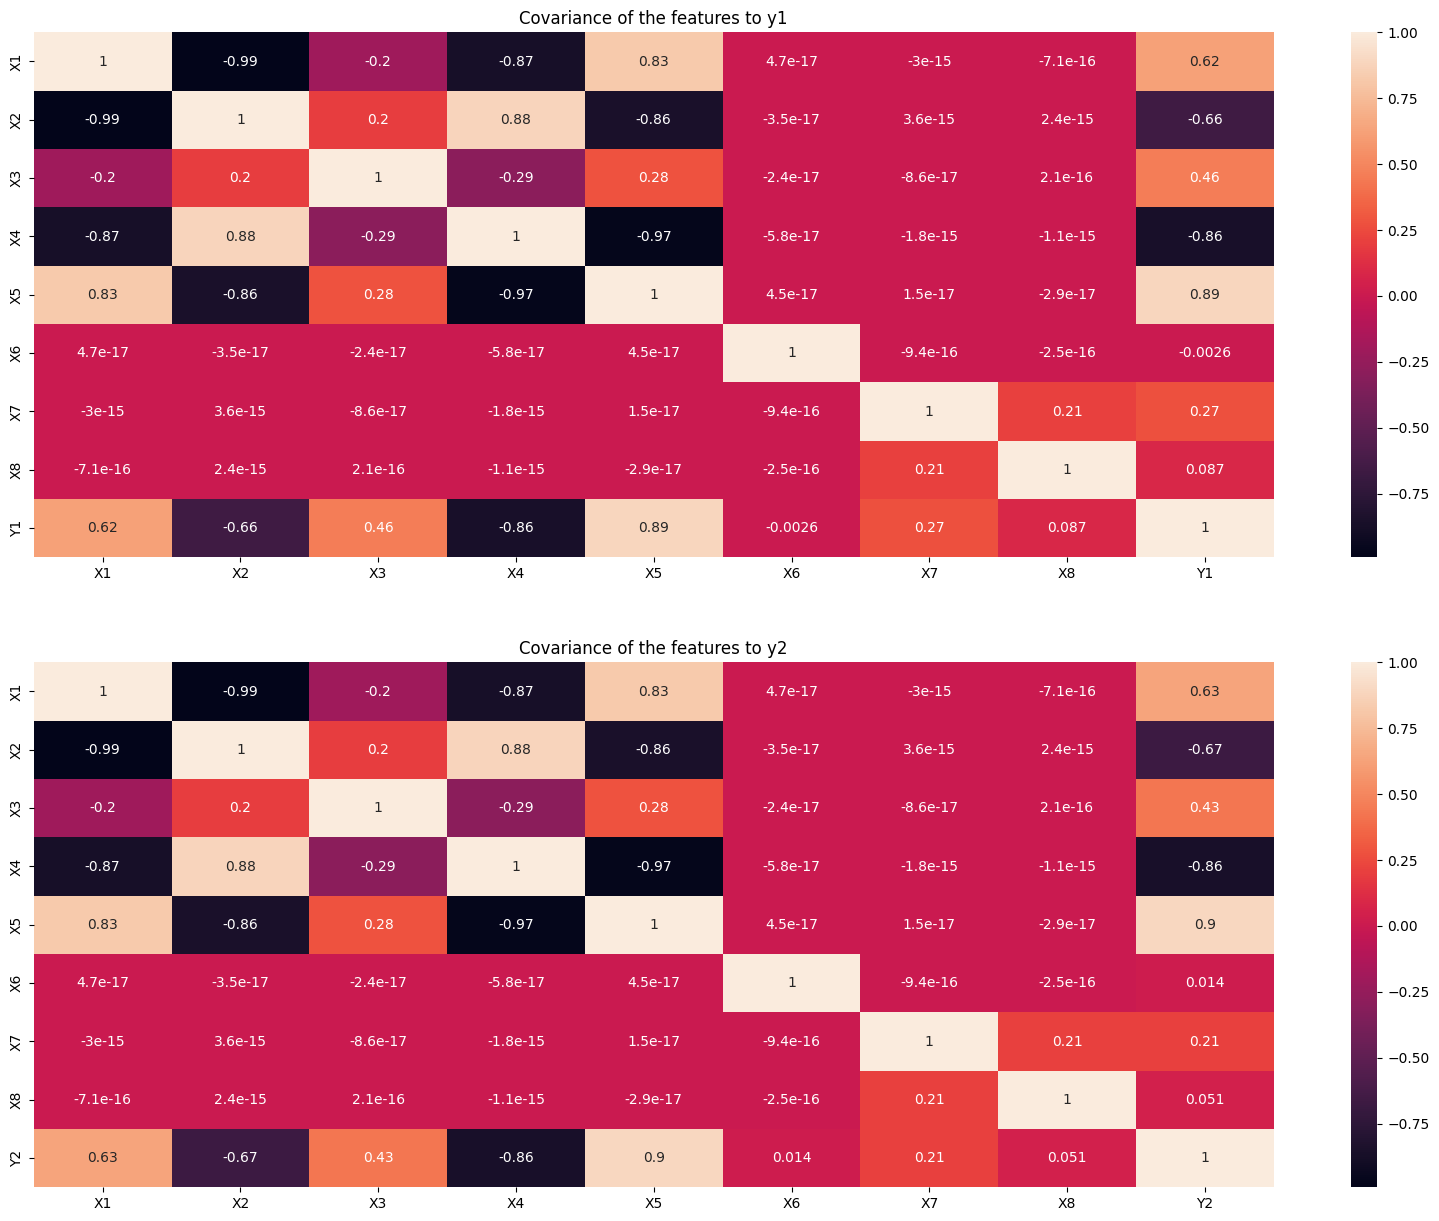

In [176]:
XY1=pd.concat([X,y['Y1']],axis=1)
XY2=pd.concat([X,y['Y2']],axis=1)

c1 = XY1.corr()
c2 = XY2.corr()
plt.figure(figsize=(20,15))

plt.subplot(2,1,1)

plt.title("Covariance of the features to y1")
sns.heatmap(c1, annot=True)
plt.subplot(2,1,2)
sns.heatmap(c2, annot=True)

plt.subplots_adjust(hspace=0.2)
plt.title("Covariance of the features to y2")
plt.show()

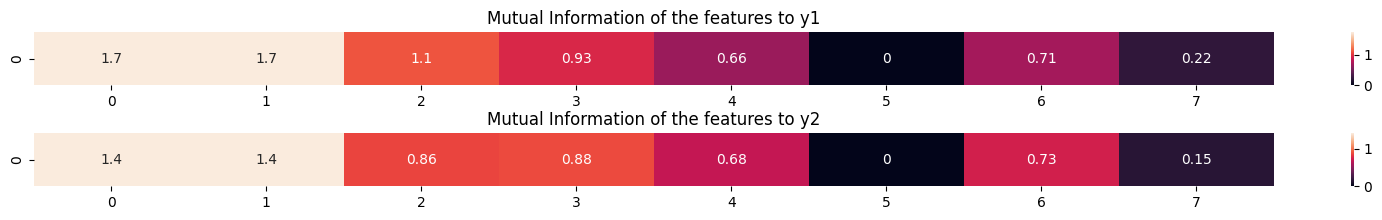

In [177]:
mifo = mutual_info_regression(X,y['Y1'])
mifo2 = mutual_info_regression(X,y['Y2'])

plt.figure(figsize=(20,2))
plt.subplot(2,1,1)
plt.title("Mutual Information of the features to y1")
sns.heatmap(pd.DataFrame(mifo).T, annot=True)
plt.subplot(2,1,2)
plt.title("Mutual Information of the features to y2")
sns.heatmap(pd.DataFrame(mifo2).T, annot=True)
plt.subplots_adjust(hspace=0.9)
plt.show()

### Conclusion
- The features show very poor linear relationships withthe output parameters, however they show strong nonlinear relationships evaluated upon Mutual information.
- In terms of non-linear relationships, feature **X6** shows no relationship with the output and feature **X8** shows relatively poor relationships, thus they are to be removed during feature selection.
- The features also hold very high ranges of values, thus needing scaling before any training can take place.

In [178]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_processed=X.copy()
X_processed.drop(['X6','X8'],axis=1,inplace=True)
X_processed = pd.DataFrame(scaler.fit_transform(X_processed),columns=X_processed.columns)

display(X_processed.describe())
display(X_processed.head())


,X1,X2,X3,X4,X5,X7
count,7.680000e+02,7.680000e+02,768.000000,7.680000e+02,768.000000,7.680000e+02
mean,-7.401487e-17,-4.163336e-16,0.000000,2.174187e-16,0.000000,1.480297e-16
std,1.000652e+00,1.000652e+00,1.000652,1.000652e+00,1.000652,1.000652e+00
min,-1.363812e+00,-1.785875e+00,-1.685854,-1.470077e+00,-1.000000,-1.760447e+00
25%,-7.725642e-01,-7.421818e-01,-0.561951,-7.915797e-01,-1.000000,-1.009323e+00
50%,-1.340162e-01,2.319318e-02,0.000000,1.583159e-01,0.000000,1.173631e-01
75%,6.227813e-01,7.885681e-01,0.561951,9.725122e-01,1.000000,1.244049e+00
max,2.041777e+00,1.553943e+00,2.247806,9.725122e-01,1.000000,1.244049e+00


,X1,X2,X3,X4,X5,X7
0,2.041777,-1.785875,-0.561951,-1.470077,1.0,-1.760447
1,2.041777,-1.785875,-0.561951,-1.470077,1.0,-1.760447
2,2.041777,-1.785875,-0.561951,-1.470077,1.0,-1.760447
3,2.041777,-1.785875,-0.561951,-1.470077,1.0,-1.760447
4,1.284979,-1.229239,0.000000,-1.198678,1.0,-1.760447


#**Model Selection and Evaluation**
- Multi-Layered Perceptrons will be trained on the data and their performances will be evaluated to find out the best fit model.
- Due to the regressive nature of the output they will be evaluated based on R^2 and MAE

In [179]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [180]:
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

In [181]:
mlp1= tf.keras.models.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(X_processed.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(2, activation='linear')
])
mlp2= tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_processed.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(2, activation='linear')
])
mlp3= tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_processed.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(2, activation='linear')
])
mlp4= tf.keras.models.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(X_processed.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(2, activation='linear')
])
mlp5= tf.keras.models.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(X_processed.shape[1],)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(2, activation='linear')
])
mlp1.name='MLP1'
mlp2.name='MLP2'
mlp3.name='MLP3'
mlp4.name='MLP4'
mlp5.name='MLP5'

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [182]:
mlp1.compile(optimizer='adam', loss='mse', metrics=['mae'])
mlp2.compile(optimizer='adam', loss='mse', metrics=['mae'])
mlp3.compile(optimizer='adam', loss='mse', metrics=['mae'])
mlp4.compile(optimizer='adam', loss='mse', metrics=['mae'])
mlp5.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [183]:
mlp1.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2)
mlp2.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2)
mlp3.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2)
mlp4.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2)
mlp5.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2)

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 634.8366 - mae: 23.1970 - val_loss: 559.5515 - val_mae: 21.7692
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 566.8859 - mae: 21.8180 - val_loss: 461.6703 - val_mae: 19.5912
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 417.0185 - mae: 18.2906 - val_loss: 250.8422 - val_mae: 13.7180
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 161.5781 - mae: 10.0046 - val_loss: 58.0734 - val_mae: 5.1643
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 58.7370 - mae: 5.0880 - val_loss: 50.4516 - val_mae: 4.3538
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 36.4715 - mae: 4.0147 - val_loss: 34.2801 - val_mae: 3.9729
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 30.7295 - mae: 3.8395 - val_loss: 30.3028 - val_mae: 3.8676
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 27.1525 - mae: 3.7093 - val_loss: 28.3314 - val_mae: 3.7854
Epoch 9/30
16/16 ━━━━━━━━━━━━━━━━━━━

In [171]:
display(mlp1.summary())
display(mlp2.summary())
display(mlp3.summary())
display(mlp4.summary())
display(mlp5.summary())

Model: "MLP1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_127 (Dense)               │ (None, 128)            │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_129 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_130 (Dense)               │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,298 (44.13 KB)

 Trainable params: 11,298 (44.13 KB)

 Non-trainable params: 0 (0.00 B)

None

... (20 outputs left out)

 Total params: 21,602 (84.38 KB)

 Trainable params: 21,602 (84.38 KB)

 Non-trainable params: 0 (0.00 B)

None

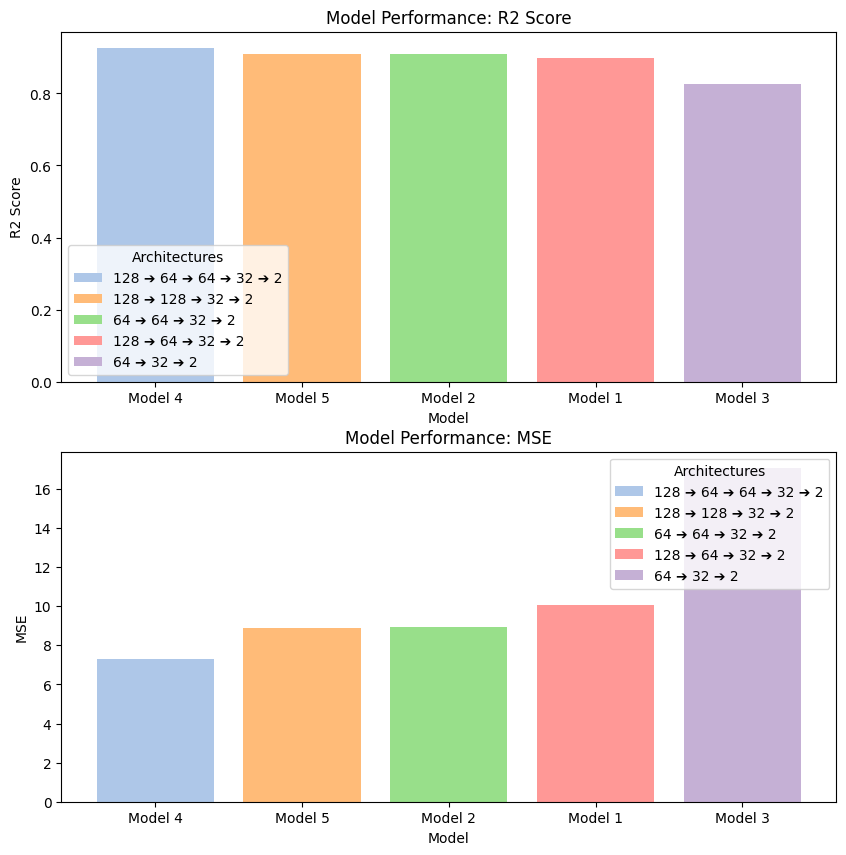

,Model,Architecture,R2 Score,MSE
3,Model 4,128 ➔ 64 ➔ 64 ➔ 32 ➔ 2,0.924967,7.321872
4,Model 5,128 ➔ 128 ➔ 32 ➔ 2,0.908897,8.898159
1,Model 2,64 ➔ 64 ➔ 32 ➔ 2,0.908364,8.941851
0,Model 1,128 ➔ 64 ➔ 32 ➔ 2,0.897067,10.065363
2,Model 3,64 ➔ 32 ➔ 2,0.825213,17.055216


In [207]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Model 1": mlp1,
    "Model 2": mlp2,
    "Model 3": mlp3,
    "Model 4": mlp4,
    "Model 5": mlp5,
}

results =[]
for name, model in models.items():
    y_pred = model.predict(X_test, verbose=0)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    layers = [
        str(l.units) for l in model.layers if hasattr(l, "units") and l.units != 2
    ]
    results.append(
        {
            "Model": name,
            "Architecture": f"{' ➔ '.join(layers)} ➔ 2",
            "R2 Score": r2,
            "MSE": mse,
        }
    )

performance_df = pd.DataFrame(results).sort_values(
    by="R2 Score", ascending=False
)

colors = ["#AEC7E8", "#FFBB78", "#98DF8A", "#FF9896", "#C5B0D5"]


plt.figure(figsize=(10, 10))

# Subplot 1: R2 Score
plt.subplot(2, 1, 1)
bars1 = plt.bar(
    performance_df["Model"],
    performance_df["R2 Score"],
    color=colors,
)
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("Model Performance: R2 Score")
plt.legend(
    bars1,
    performance_df["Architecture"],
    title="Architectures",
    loc="lower left",
)

# Subplot 2: MSE
plt.subplot(2, 1, 2)
bars2 = plt.bar(
    performance_df["Model"],
    performance_df["MSE"],
    color=colors,
)
plt.xlabel("Model")
plt.ylabel("MSE")
plt.title("Model Performance: MSE")
plt.legend(
    bars2,
    performance_df["Architecture"],
    title="Architectures",
    loc="upper right",
)

plt.subplots_adjust(hspace=0.2)
plt.show()
display(performance_df)


# **Conclusion**
- Architectural optimization demonstrated that increasing model depth was crucial for this problem; the 4-layer architecture (128 ➔ 64 ➔ 64 ➔ 32) achieved the highest predictive accuracy, explaining 92.50% of the total variance with the lowest error rate (MSE = 7.32).
- Restricting the network's capacity or reducing its depth (as seen in Models 1 and 3) significantly degraded performance, proving that the complex, non-linear thermodynamic relationships governing these energy loads require a deeper hierarchical network layout to generalize effectively.